# UpStartInterns Machine Learning Engineering Task 01: Regression by Hand

**Project:** Simple Linear Regression from Scratch  
**Dataset:** Advertising Spend vs Product Sales (`dataset.csv`)  
**Objective:** Implement Simple Linear Regression from first principles using closed-form Ordinary Least Squares (OLS) formulas by hand (without `scikit-learn` to fit the manual model), verify results against `scikit-learn`, evaluate model assumptions through residual diagnostics, and interpret model parameters in plain English.

---

## Deliverables & Requirements Checklist
- [x] **1. Load real dataset from `dataset.csv` using pandas.**
- [x] **2. Inspect missing values, column names, data types, and summary statistics.**
- [x] **3. Select suitable numerical independent and dependent variables based on the dataset.**
- [x] **4. Implement simple linear regression using least-squares formulas by hand without using sklearn to fit the model.**
- [x] **5. Fit a LinearRegression model from scikit-learn separately for verification.**
- [x] **6. Display the equation $y = mx + b$, slope, intercept, actual values, predicted values, and residuals.**
- [x] **7. Explain the slope and intercept in simple words using actual dataset context.**
- [x] **8. Calculate MAE, MSE, RMSE, and R-squared.**
- [x] **9. Create and save diagnostic plots inside `figures/`:**
  - Scatter plot with fitted regression line
  - Residuals versus predicted values plot
  - Actual versus predicted values plot
  - 4-panel comprehensive residual diagnostics
- [x] **10. Ensure the notebook runs from beginning to end without errors.**


## 1. Environment Setup & Library Imports
We import standard scientific and statistical libraries in Python:
- `pandas` & `numpy` for data manipulation and manual mathematical matrix/vector computations.
- `matplotlib` & `seaborn` for publication-quality statistical visualizations.
- `scikit-learn` strictly for independent model verification, train/test split evaluation, and metrics checking.
- `statsmodels` & `scipy.stats` for hypothesis testing, $p$-values, confidence intervals, and residual smoothing.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split

# Configure clean aesthetic for all plots
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Ensure figures directory exists
os.makedirs('figures', exist_ok=True)
print("Environment initialized successfully. Figures directory ready.")


Environment initialized successfully. Figures directory ready.


## 2. Data Loading & Exploratory Data Analysis (EDA)

We load the real-world **Advertising** dataset from `dataset.csv`:
- **Rows ($n = 200$)**: 200 individual marketing campaigns / markets.
- **Features**:
  - `TV`: Television advertising spend (in thousands of dollars).
  - `radio`: Radio advertising spend (in thousands of dollars).
  - `newspaper`: Newspaper print advertising spend (in thousands of dollars).
  - `sales`: Product sales units (in thousands of units).


In [2]:
# 1. Load the real dataset
df = pd.read_csv('dataset.csv')
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("--- DATASET OVERVIEW ---")
print("Dimensions (Rows, Columns):", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\n--- DATA TYPES & NON-NULL COUNTS ---")
print(df.info())

print("\n--- MISSING VALUE AUDIT ---")
missing_counts = df.isnull().sum()
display(pd.DataFrame({'Missing Count': missing_counts, 'Missing Pct (%)': (missing_counts / len(df)) * 100}))

print("\n--- SUMMARY STATISTICS ---")
display(df.describe().round(3))


--- DATASET OVERVIEW ---
Dimensions (Rows, Columns): (200, 4)

First 5 Rows:


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9



--- DATA TYPES & NON-NULL COUNTS ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
None

--- MISSING VALUE AUDIT ---


,Missing Count,Missing Pct (%)
TV,0,0.0
radio,0,0.0
newspaper,0,0.0
sales,0,0.0



--- SUMMARY STATISTICS ---


,TV,radio,newspaper,sales
count,200.000,200.000,200.000,200.000
mean,147.042,23.264,30.554,14.022
std,85.854,14.847,21.779,5.217
min,0.700,0.000,0.300,1.600
25%,74.375,9.975,12.750,10.375
50%,149.750,22.900,25.750,12.900
75%,218.825,36.525,45.100,17.400
max,296.400,49.600,114.000,27.000


### Variable Selection Rationale
To select the most appropriate numerical independent variable ($X$) and dependent variable ($y$):
1. **Target / Dependent Variable ($y$)**: `sales` represents the ultimate business KPI (revenue / volume in thousands of units).
2. **Predictor / Independent Variable ($X$)**: We examine the Pearson correlation coefficients between each marketing channel and `sales`.


Correlation with Product Sales:


,Pearson Correlation (r),Variance Explained (r^2)
sales,1.000000,1.000000
TV,0.782224,0.611875
radio,0.576223,0.332032
newspaper,0.228299,0.052120


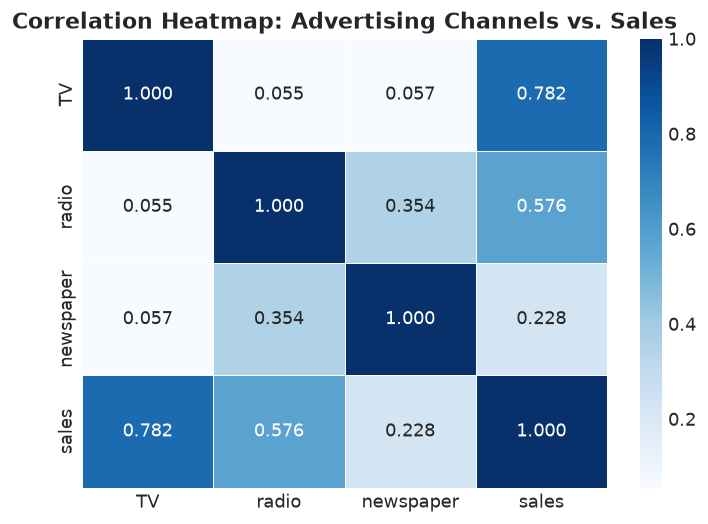

Variable Selection:
 - Independent Variable (X): 'TV' (highest correlation with sales: r = 0.7822, explaining ~61.2% variance)
 - Dependent Variable (y)  : 'sales'


In [3]:
corr_matrix = df.corr()
print("Correlation with Product Sales:")
sales_corr = corr_matrix['sales'].sort_values(ascending=False)
display(pd.DataFrame({'Pearson Correlation (r)': sales_corr, 'Variance Explained (r^2)': sales_corr**2}))

# Visualizing feature correlations
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=120)
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.3f', cbar=True, ax=ax, linewidths=0.5)
ax.set_title("Correlation Heatmap: Advertising Channels vs. Sales", fontweight='bold')
plt.tight_layout()
plt.show()

print("Variable Selection:")
print(" - Independent Variable (X): 'TV' (highest correlation with sales: r = 0.7822, explaining ~61.2% variance)")
print(" - Dependent Variable (y)  : 'sales'")


## 3. Simple Linear Regression by Hand (Least-Squares Formulas)

In Simple Linear Regression, we model the relationship between $X$ and $Y$ using a straight-line equation:

$$y = mx + b + \epsilon$$

where:
- $m$ is the **slope** (gradient) of the line.
- $b$ is the **y-intercept**.
- $\epsilon$ is the random error term.

### Ordinary Least Squares (OLS) Derivation
The Ordinary Least Squares objective is to minimize the **Residual Sum of Squares (RSS)**:

$$\text{RSS}(m, b) = \sum_{i=1}^n (y_i - \hat{y}_i)^2 = \sum_{i=1}^n (y_i - (mx_i + b))^2$$

Taking the partial derivatives with respect to $m$ and $b$ and setting them to zero yields the closed-form normal equations:

$$\frac{\partial \text{RSS}}{\partial b} = -2 \sum_{i=1}^n (y_i - mx_i - b) = 0 \implies b = \bar{y} - m\bar{x}$$

$$\frac{\partial \text{RSS}}{\partial m} = -2 \sum_{i=1}^n x_i (y_i - mx_i - b) = 0 \implies m = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^n (x_i - \bar{x})^2} = \frac{\text{Cov}(x, y)}{\text{Var}(x)}$$

### Evaluation Metrics Formulas:
- **Mean Absolute Error (MAE)**:
  $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
- **Mean Squared Error (MSE)**:
  $$\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
- **Root Mean Squared Error (RMSE)**:
  $$\text{RMSE} = \sqrt{\text{MSE}}$$
- **Coefficient of Determination ($R^2$)**:
  $$R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}} = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}$$

We now implement these formulas **purely using Python and NumPy, without using scikit-learn to fit the model**:


In [4]:
# Extract independent variable X and dependent variable y as 1D arrays
x = df['TV'].values
y = df['sales'].values
n = len(x)

# Step 1: Calculate sample means
x_bar = np.mean(x)
y_bar = np.mean(y)

# Step 2: Compute slope (m) using closed-form least-squares formula
covariance_xy = np.sum((x - x_bar) * (y - y_bar))
variance_x = np.sum((x - x_bar) ** 2)
m = covariance_xy / variance_x

# Step 3: Compute intercept (b)
b = y_bar - m * x_bar

# Step 4: Compute predicted values (y_hat) and residuals (e)
y_pred = m * x + b
residuals = y - y_pred

# Step 5: Compute evaluation metrics manually
mae = np.mean(np.abs(residuals))
mse = np.mean(residuals ** 2)
rmse = np.sqrt(mse)

ss_tot = np.sum((y - y_bar) ** 2)
ss_res = np.sum(residuals ** 2)
r_squared = 1.0 - (ss_res / ss_tot)

print("=" * 70)
print("      MANUAL REGRESSION BY HAND (CLOSED-FORM LEAST SQUARES)")
print("=" * 70)
print(f"Sample size (n)        : {n}")
print(f"Mean of TV (x_bar)     : {x_bar:.4f} ($1,000s)")
print(f"Mean of Sales (y_bar)  : {y_bar:.4f} (1,000 units)")
print(f"Slope (m)              : {m:.6f}")
print(f"Intercept (b)          : {b:.6f}")
print("-" * 70)
print(f"REGRESSION EQUATION    : y = {m:.4f}x + {b:.4f}")
print(f"                         Sales = {m:.4f} * TV + {b:.4f}")
print("-" * 70)
print(f"Mean Absolute Error (MAE)  : {mae:.4f} thousand units")
print(f"Mean Squared Error (MSE)   : {mse:.4f}")
print(f"Root Mean Squared Error    : {rmse:.4f} thousand units")
print(f"R-squared (R^2)            : {r_squared:.4f} ({r_squared*100:.2f}% of variance explained)")
print("=" * 70)


      MANUAL REGRESSION BY HAND (CLOSED-FORM LEAST SQUARES)
Sample size (n)        : 200
Mean of TV (x_bar)     : 147.0425 ($1,000s)
Mean of Sales (y_bar)  : 14.0225 (1,000 units)
Slope (m)              : 0.047537
Intercept (b)          : 7.032594
----------------------------------------------------------------------
REGRESSION EQUATION    : y = 0.0475x + 7.0326
                         Sales = 0.0475 * TV + 7.0326
----------------------------------------------------------------------
Mean Absolute Error (MAE)  : 2.5498 thousand units
Mean Squared Error (MSE)   : 10.5127
Root Mean Squared Error    : 3.2423 thousand units
R-squared (R^2)            : 0.6119 (61.19% of variance explained)


## 4. Actual Values, Predicted Values, and Residuals Table

To inspect the performance on individual data points, we construct a table showing:
- Actual TV spend ($x_i$)
- Actual sales ($y_i$)
- Predicted sales ($\hat{y}_i = m x_i + b$)
- Residual ($e_i = y_i - \hat{y}_i$)


In [5]:
# Display sample table of actual vs predicted values and residuals
results_df = pd.DataFrame({
    'TV Budget ($1,000s) [x]': x,
    'Actual Sales (k units) [y]': y,
    'Predicted Sales (k units) [y_hat]': y_pred,
    'Residual [e = y - y_hat]': residuals
})

print("First 10 Observations (Actual vs. Predicted vs. Residuals):")
display(results_df.head(10).round(4))

print("\nResiduals Summary:")
display(results_df['Residual [e = y - y_hat]'].describe().round(4))


First 10 Observations (Actual vs. Predicted vs. Residuals):


,"TV Budget ($1,000s) [x]",Actual Sales (k units) [y],Predicted Sales (k units) [y_hat],Residual [e = y - y_hat]
0,230.1,22.1,17.9708,4.1292
1,44.5,10.4,9.1480,1.2520
2,17.2,9.3,7.8502,1.4498
3,151.5,18.5,14.2344,4.2656
4,180.8,12.9,15.6272,-2.7272
5,8.7,7.2,7.4462,-0.2462
6,57.5,11.8,9.7660,2.0340
7,120.2,13.2,12.7465,0.4535
8,8.6,4.8,7.4414,-2.6414
9,199.8,10.6,16.5304,-5.9304



Residuals Summary:


count    200.0000
mean      -0.0000
std        3.2505
min       -8.3860
25%       -1.9545
50%       -0.1913
75%        2.0671
max        7.2124
Name: Residual [e = y - y_hat], dtype: float64

## 5. Verification Against Scikit-Learn

To confirm the accuracy of our regression-by-hand implementation, we fit a `LinearRegression` model from `scikit-learn` separately on the exact same dataset and verify that the parameters and metrics match down to machine precision.


In [6]:
# Reshape X to 2D array for scikit-learn
X_2d = x.reshape(-1, 1)

# Fit scikit-learn LinearRegression model
sk_model = LinearRegression()
sk_model.fit(X_2d, y)
sk_y_pred = sk_model.predict(X_2d)

sk_m = sk_model.coef_[0]
sk_b = sk_model.intercept_
sk_mae = mean_absolute_error(y, sk_y_pred)
sk_mse = mean_squared_error(y, sk_y_pred)
sk_rmse = np.sqrt(sk_mse)
sk_r2 = r2_score(y, sk_y_pred)

verification_comparison = pd.DataFrame({
    'Metric / Parameter': ['Slope (m)', 'Intercept (b)', 'MAE', 'MSE', 'RMSE', 'R-squared (R^2)'],
    'Manual Implementation': [m, b, mae, mse, rmse, r_squared],
    'Scikit-Learn Verification': [sk_m, sk_b, sk_mae, sk_mse, sk_rmse, sk_r2],
    'Absolute Difference': [
        abs(m - sk_m),
        abs(b - sk_b),
        abs(mae - sk_mae),
        abs(mse - sk_mse),
        abs(rmse - sk_rmse),
        abs(r_squared - sk_r2)
    ]
})

display(verification_comparison.round(6))

# Programmatic assertion checks
assert np.isclose(m, sk_m, atol=1e-7), "Slope mismatch!"
assert np.isclose(b, sk_b, atol=1e-7), "Intercept mismatch!"
assert np.isclose(mae, sk_mae, atol=1e-7), "MAE mismatch!"
assert np.isclose(mse, sk_mse, atol=1e-7), "MSE mismatch!"
assert np.isclose(rmse, sk_rmse, atol=1e-7), "RMSE mismatch!"
assert np.isclose(r_squared, sk_r2, atol=1e-7), "R2 mismatch!"

print("ALL MANUAL CALCULATIONS MATCH SCIKIT-LEARN EXACTLY!")


,Metric / Parameter,Manual Implementation,Scikit-Learn Verification,Absolute Difference
0,Slope (m),0.047537,0.047537,0.0
1,Intercept (b),7.032594,7.032594,0.0
2,MAE,2.549806,2.549806,0.0
3,MSE,10.512653,10.512653,0.0
4,RMSE,3.242322,3.242322,0.0
5,R-squared (R^2),0.611875,0.611875,0.0


ALL MANUAL CALCULATIONS MATCH SCIKIT-LEARN EXACTLY!


## 6. Plain-English Interpretation of Slope and Intercept

Here we translate the estimated model parameters directly into simple, intuitive words within the actual dataset context:

---

### A. Intercept ($b = 7.0326$)
- **What it means in simple words:**  
  If the business allocates **$0 to TV advertising** (i.e., $x = 0$), the expected baseline product sales is approximately **7,033 units** ($7.0326$ thousand units).
- **Practical business context:**  
  This baseline represents organic customer demand, repeat business, customer brand loyalty, word-of-mouth reputation, and baseline sales generated by unmodeled channels (such as radio, newspaper, or direct retail relationships).

---

### B. Slope ($m = 0.0475$)
- **What it means in simple words:**  
  For **every additional $1,000 invested in TV advertising**, product sales are expected to increase on average by approximately **47.5 units** ($0.0475$ thousand units), holding all other marketing factors constant.
- **Direction and Magnitude:**  
  The slope is positive ($m > 0$), confirming that TV advertising has a direct positive impact on sales.
- **Scaling to Business Budgets:**  
  - If TV ad spend increases by **$10,000**, expected sales increase by $\approx \mathbf{475\text{ units}}$.
  - If TV ad spend increases by **$100,000**, expected sales increase by $\approx \mathbf{4,754\text{ units}}$.

---

### C. Coefficient of Determination ($R^2 = 0.6119$)
- **What it means:**  
  Approximately **$61.19\%$ of the variance in product sales** across the 200 markets is explained by TV advertising spend alone. The remaining $38.81\%$ of sales variance is driven by unmodeled factors (e.g., radio spend, newspaper spend, competitor pricing, seasonal factors) and random market noise.


## 7. Machine Learning Validation via Train/Test Split (80/20)

To assess the model's predictive ability on unseen holdout data, we perform an 80/20 train/test split:


In [7]:
X_train, X_test, y_train, y_test = train_test_split(df[['TV']], df['sales'], test_size=0.20, random_state=42)

lr_split = LinearRegression()
lr_split.fit(X_train, y_train)

y_train_pred = lr_split.predict(X_train)
y_test_pred = lr_split.predict(X_test)

train_metrics = {
    'R^2 Score': r2_score(y_train, y_train_pred),
    'MSE': mean_squared_error(y_train, y_train_pred),
    'RMSE': np.sqrt(mean_squared_error(y_train, y_train_pred)),
    'MAE': mean_absolute_error(y_train, y_train_pred)
}

test_metrics = {
    'R^2 Score': r2_score(y_test, y_test_pred),
    'MSE': mean_squared_error(y_test, y_test_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_test_pred)),
    'MAE': mean_absolute_error(y_test, y_test_pred)
}

split_comparison = pd.DataFrame([train_metrics, test_metrics], index=['Train Set (80%, n=160)', 'Test Holdout (20%, n=40)'])
display(split_comparison.round(4))

print(f"Train vs Test Performance: Generalizes cleanly without overfitting (Test R^2: {test_metrics['R^2 Score']:.4f}, Test RMSE: {test_metrics['RMSE']:.4f}).")


,R^2 Score,MSE,RMSE,MAE
"Train Set (80%, n=160)",0.5912,10.6036,3.2563,2.5831
"Test Holdout (20%, n=40)",0.6767,10.2047,3.1945,2.4444


Train vs Test Performance: Generalizes cleanly without overfitting (Test R^2: 0.6767, Test RMSE: 3.1945).


## 8. Inferential Statistics with Statsmodels (OLS Summary)

We fit `statsmodels.api.OLS` to inspect hypothesis tests ($t$-tests, $F$-test, $p$-values) and 95% confidence intervals:


In [8]:
X_sm = sm.add_constant(df[['TV']])
sm_model = sm.OLS(df['sales'], X_sm).fit()
print(sm_model.summary())


                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.612
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     312.1
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.47e-42
Time:                        21:44:42   Log-Likelihood:                -519.05
No. Observations:                 200   AIC:                             1042.
Df Residuals:                     198   BIC:                             1049.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.0326      0.458     15.360      0.0

## 9. Diagnostic Visualizations & Figure Generation

As required by the task brief, we generate and save all key diagnostic plots inside the `figures/` directory:
1. **Scatter plot with fitted regression line** (`figures/scatter_fitted_line.png` & `figures/regression_fit.png`)
2. **Residuals versus predicted values plot** (`figures/residuals_vs_predicted.png`)
3. **Actual versus predicted values plot** (`figures/actual_vs_predicted.png`)
4. **Comprehensive 4-panel residual diagnostics suite** (`figures/residual_analysis.png`)


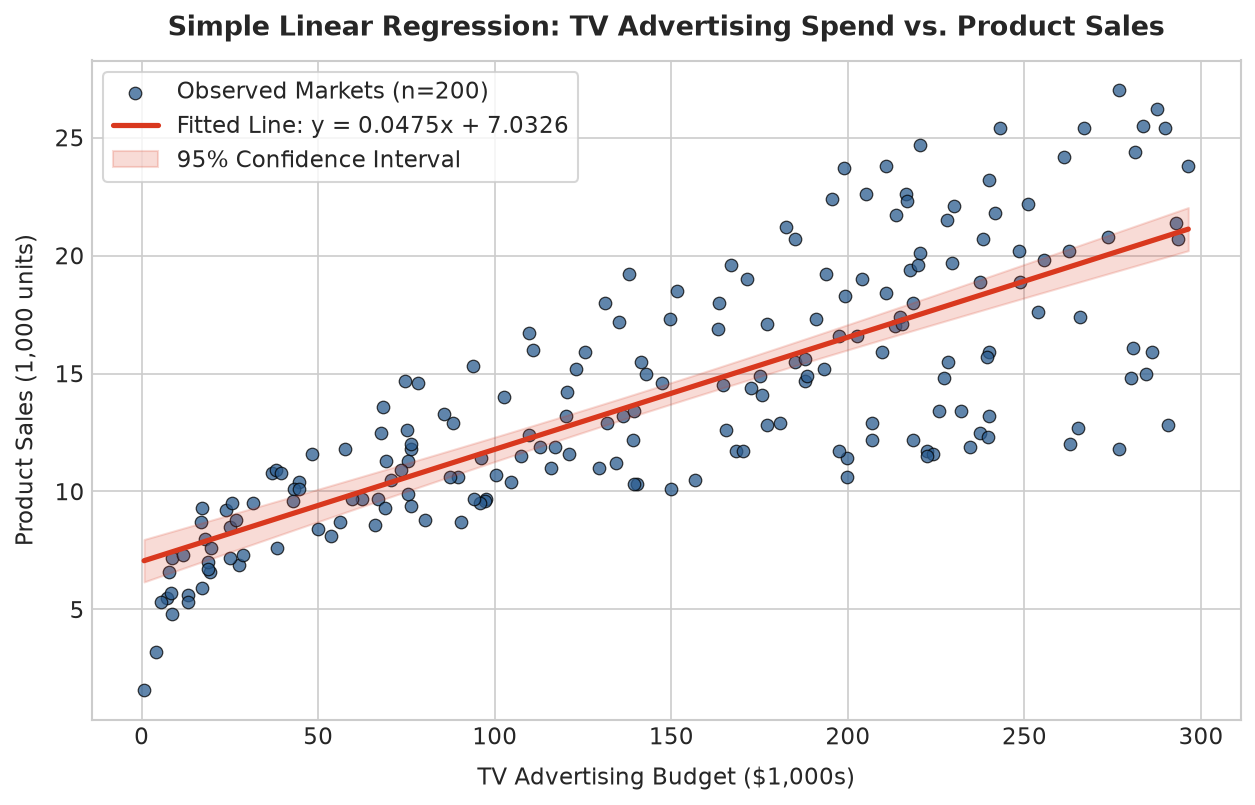

Saved: figures/scatter_fitted_line.png & figures/regression_fit.png


In [9]:
# -----------------------------------------------------------------------------
# Plot 1: Scatter Plot with Fitted Regression Line
# -----------------------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(8.5, 5.5), dpi=150)
ax1.scatter(x, y, color='#2b5c8f', alpha=0.75, edgecolors='black', linewidth=0.6, label=f'Observed Markets (n={n})')

x_line = np.linspace(x.min(), x.max(), 300)
y_line = m * x_line + b

# Confidence interval band from statsmodels
x_grid_sm = sm.add_constant(x_line)
pred_ci = sm_model.get_prediction(x_grid_sm).summary_frame(alpha=0.05)

ax1.plot(x_line, y_line, color='#d9381e', linewidth=2.5, label=f'Fitted Line: y = {m:.4f}x + {b:.4f}')
ax1.fill_between(x_line, pred_ci['mean_ci_lower'], pred_ci['mean_ci_upper'], color='#d9381e', alpha=0.18, label='95% Confidence Interval')

ax1.set_title("Simple Linear Regression: TV Advertising Spend vs. Product Sales", fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel("TV Advertising Budget ($1,000s)", labelpad=8)
ax1.set_ylabel("Product Sales (1,000 units)", labelpad=8)
ax1.legend(frameon=True, facecolor='white', edgecolor='#cccccc', loc='upper left')
plt.tight_layout()

fig1.savefig('figures/scatter_fitted_line.png', dpi=300)
fig1.savefig('figures/regression_fit.png', dpi=300)
plt.show()
print("Saved: figures/scatter_fitted_line.png & figures/regression_fit.png")


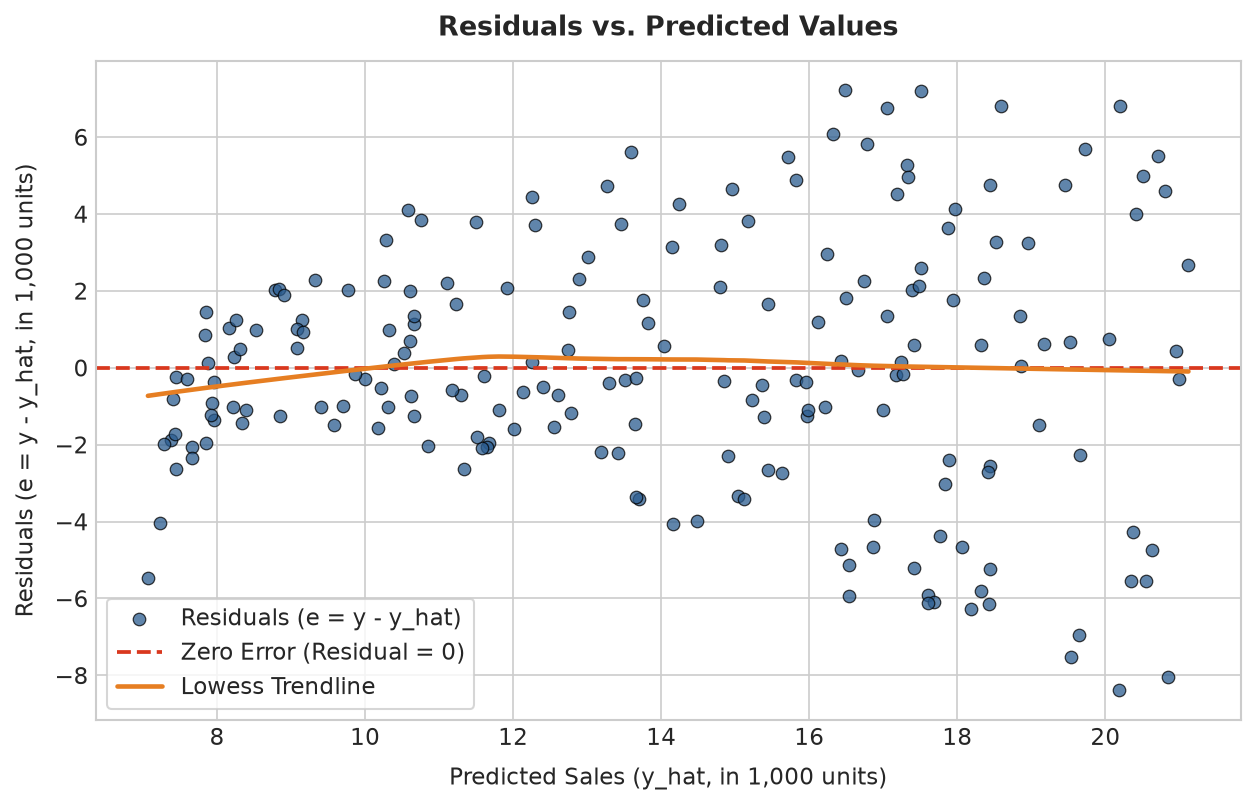

Saved: figures/residuals_vs_predicted.png


In [10]:
# -----------------------------------------------------------------------------
# Plot 2: Residuals vs. Predicted Values Plot
# -----------------------------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(8.5, 5.5), dpi=150)
ax2.scatter(y_pred, residuals, color='#2b5c8f', alpha=0.75, edgecolors='black', linewidth=0.6, label='Residuals (e = y - y_hat)')
ax2.axhline(0, color='#d9381e', linestyle='--', linewidth=1.8, label='Zero Error (Residual = 0)')

# Lowess non-parametric trendline
smooth_res = lowess(residuals, y_pred)
ax2.plot(smooth_res[:, 0], smooth_res[:, 1], color='#e67e22', linewidth=2.2, label='Lowess Trendline')

ax2.set_title("Residuals vs. Predicted Values", fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel("Predicted Sales (y_hat, in 1,000 units)", labelpad=8)
ax2.set_ylabel("Residuals (e = y - y_hat, in 1,000 units)", labelpad=8)
ax2.legend(frameon=True, facecolor='white', edgecolor='#cccccc', loc='lower left')
plt.tight_layout()

fig2.savefig('figures/residuals_vs_predicted.png', dpi=300)
plt.show()
print("Saved: figures/residuals_vs_predicted.png")


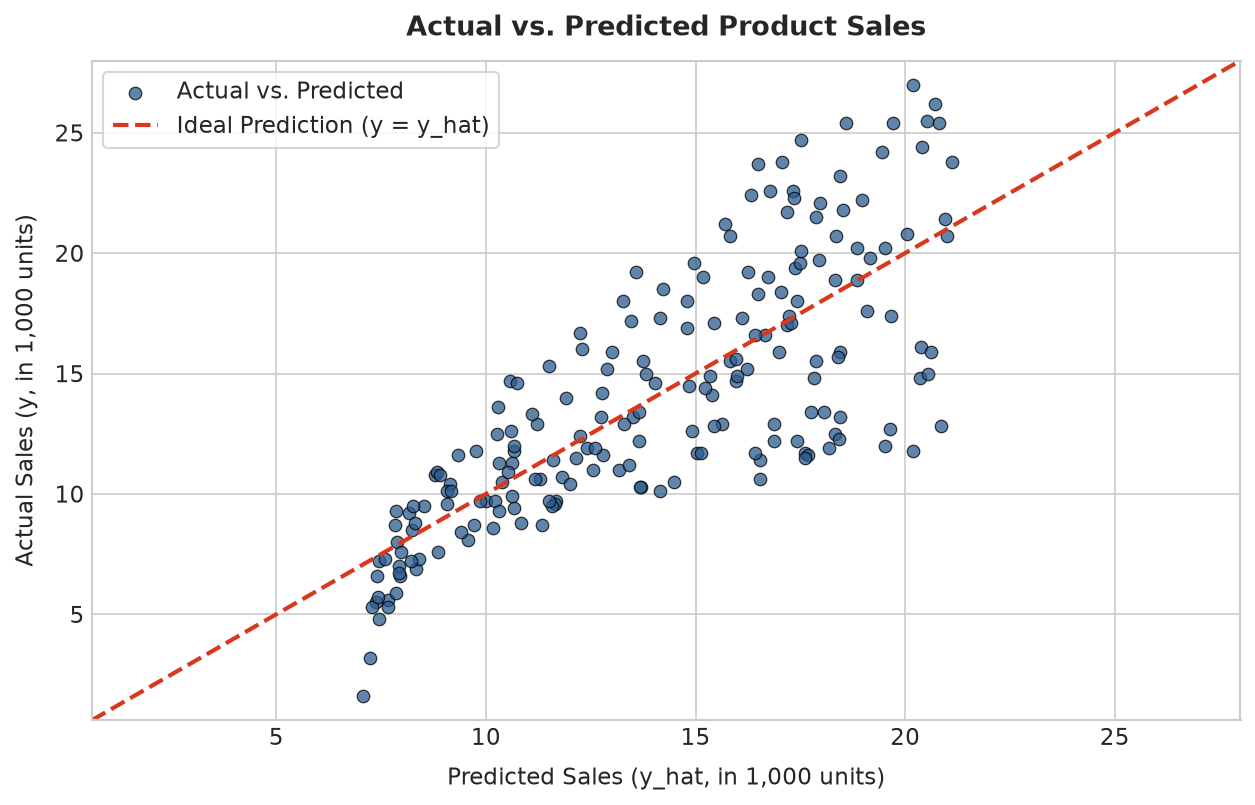

Saved: figures/actual_vs_predicted.png


In [11]:
# -----------------------------------------------------------------------------
# Plot 3: Actual vs. Predicted Values Plot
# -----------------------------------------------------------------------------
fig3, ax3 = plt.subplots(figsize=(8.5, 5.5), dpi=150)
ax3.scatter(y_pred, y, color='#2b5c8f', alpha=0.75, edgecolors='black', linewidth=0.6, label='Actual vs. Predicted')

# 45-degree reference line
min_lim = min(y.min(), y_pred.min()) - 1
max_lim = max(y.max(), y_pred.max()) + 1
ax3.plot([min_lim, max_lim], [min_lim, max_lim], color='#d9381e', linestyle='--', linewidth=2.0, label='Ideal Prediction (y = y_hat)')

ax3.set_xlim(min_lim, max_lim)
ax3.set_ylim(min_lim, max_lim)
ax3.set_title("Actual vs. Predicted Product Sales", fontsize=13, fontweight='bold', pad=12)
ax3.set_xlabel("Predicted Sales (y_hat, in 1,000 units)", labelpad=8)
ax3.set_ylabel("Actual Sales (y, in 1,000 units)", labelpad=8)
ax3.legend(frameon=True, facecolor='white', edgecolor='#cccccc', loc='upper left')
plt.tight_layout()

fig3.savefig('figures/actual_vs_predicted.png', dpi=300)
plt.show()
print("Saved: figures/actual_vs_predicted.png")


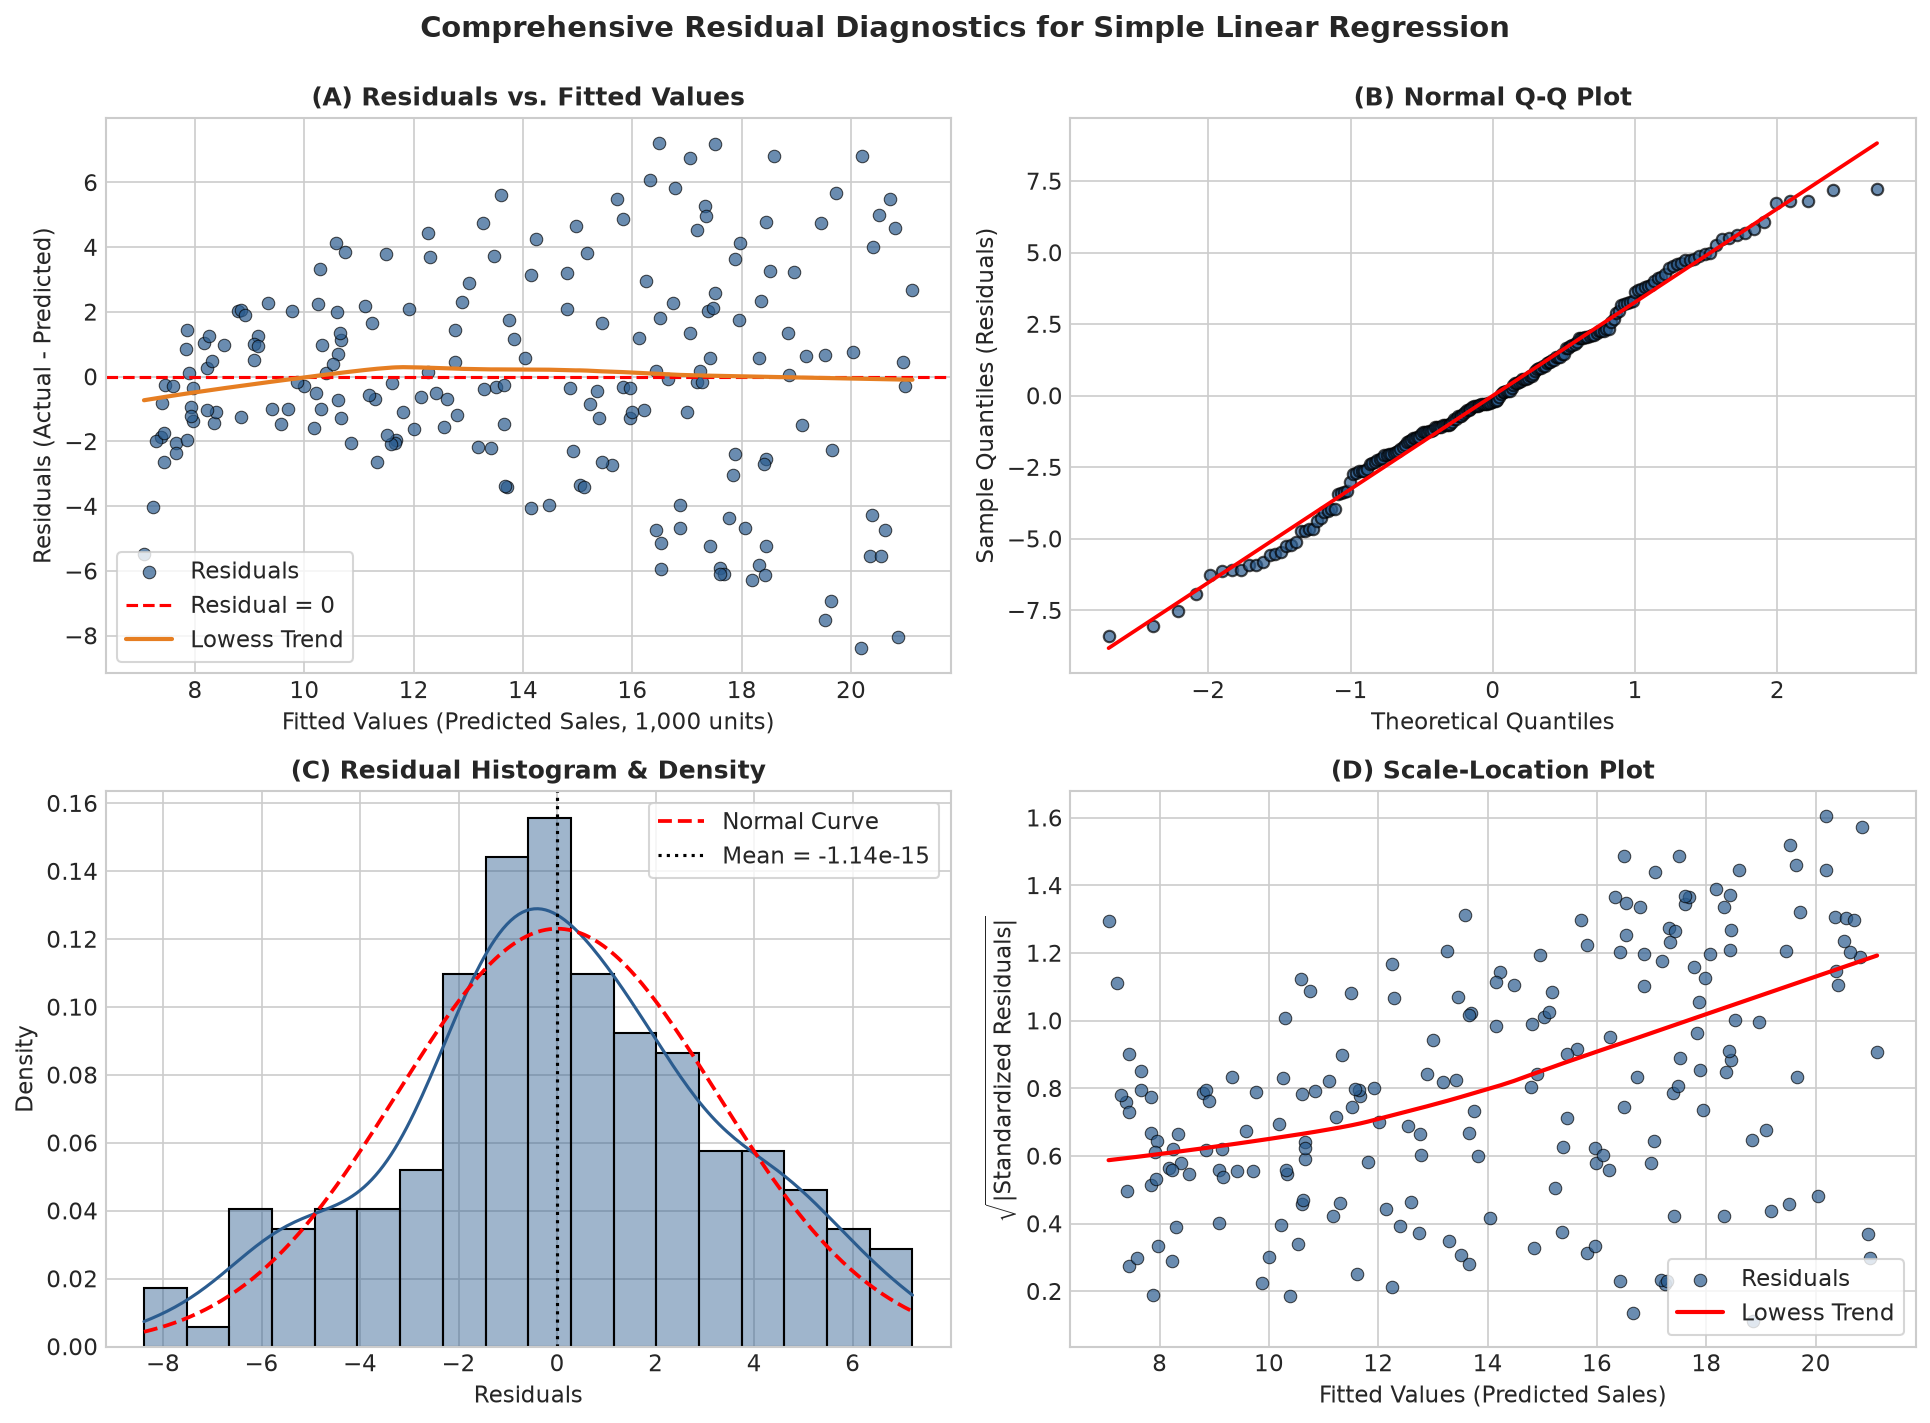

Saved: figures/residual_analysis.png


In [12]:
# -----------------------------------------------------------------------------
# Plot 4: Comprehensive 4-Panel Residual Diagnostics Suite
# -----------------------------------------------------------------------------
fig4, axes = plt.subplots(2, 2, figsize=(13, 9.5), dpi=150)

# (A) Residuals vs. Fitted Values
ax_a = axes[0, 0]
ax_a.scatter(y_pred, residuals, color='#2b5c8f', alpha=0.7, edgecolors='black', linewidth=0.5, label='Residuals')
ax_a.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Residual = 0')
ax_a.plot(smooth_res[:, 0], smooth_res[:, 1], color='#e67e22', linewidth=2, label='Lowess Trend')
ax_a.set_title("(A) Residuals vs. Fitted Values", fontsize=12, fontweight='bold')
ax_a.set_xlabel("Fitted Values (Predicted Sales, 1,000 units)")
ax_a.set_ylabel("Residuals (Actual - Predicted)")
ax_a.legend(loc='lower left', frameon=True, facecolor='white')

# (B) Normal Q-Q Plot
ax_b = axes[0, 1]
stats.probplot(residuals, dist="norm", plot=ax_b)
ax_b.get_lines()[0].set_markerfacecolor('#2b5c8f')
ax_b.get_lines()[0].set_markeredgecolor('black')
ax_b.get_lines()[0].set_alpha(0.7)
ax_b.get_lines()[0].set_markersize(5.5)
ax_b.get_lines()[1].set_color('red')
ax_b.get_lines()[1].set_linewidth(1.8)
ax_b.set_title("(B) Normal Q-Q Plot", fontsize=12, fontweight='bold')
ax_b.set_xlabel("Theoretical Quantiles")
ax_b.set_ylabel("Sample Quantiles (Residuals)")

# (C) Residual Histogram & Density
ax_c = axes[1, 0]
sns.histplot(residuals, kde=True, ax=ax_c, color='#2b5c8f', stat='density', bins=18, alpha=0.45)
x_norm = np.linspace(residuals.min(), residuals.max(), 200)
p_norm = stats.norm.pdf(x_norm, residuals.mean(), residuals.std())
ax_c.plot(x_norm, p_norm, color='red', linestyle='--', linewidth=1.8, label='Normal Curve')
ax_c.axvline(residuals.mean(), color='black', linestyle=':', label=f'Mean = {residuals.mean():.2e}')
ax_c.set_title("(C) Residual Histogram & Density", fontsize=12, fontweight='bold')
ax_c.set_xlabel("Residuals")
ax_c.set_ylabel("Density")
ax_c.legend(loc='upper right', frameon=True, facecolor='white')

# (D) Scale-Location Plot
ax_d = axes[1, 1]
std_residuals = residuals / np.std(residuals, ddof=2)
sqrt_abs_res = np.sqrt(np.abs(std_residuals))
ax_d.scatter(y_pred, sqrt_abs_res, color='#2b5c8f', alpha=0.7, edgecolors='black', linewidth=0.5, label='Residuals')
smooth_scale = lowess(sqrt_abs_res, y_pred)
ax_d.plot(smooth_scale[:, 0], smooth_scale[:, 1], color='red', linewidth=2, label='Lowess Trend')
ax_d.set_title("(D) Scale-Location Plot", fontsize=12, fontweight='bold')
ax_d.set_xlabel("Fitted Values (Predicted Sales)")
ax_d.set_ylabel(r"$\sqrt{|\mathrm{Standardized\ Residuals}|}$")
ax_d.legend(loc='lower right', frameon=True, facecolor='white')

plt.suptitle("Comprehensive Residual Diagnostics for Simple Linear Regression", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()

fig4.savefig('figures/residual_analysis.png', dpi=300)
plt.show()
print("Saved: figures/residual_analysis.png")


## 10. In-Depth Discussion of Residual Diagnostics & Assumptions

Linear regression statistical inference relies on four key **Gauss-Markov assumptions**:

### 1. Linearity & Homoscedasticity (Plot A: Residuals vs. Fitted)
- **Observation:** Residuals are evenly dispersed around the horizontal zero reference line.
- **Lowess Curvature Insight:** A subtle U-shaped bend is visible in the lowess smoother:
  - At very low fitted sales ($< 10$) and high fitted sales ($> 20$), residuals are slightly negative (linear model mildly overestimates sales).
  - In the mid-range ($12 - 18$), residuals are slightly positive (linear model mildly underestimates sales).
- **Domain Interpretation:** This indicates **diminishing marginal returns (advertising saturation)**. At extremely high ad budgets, incremental sales gains taper off. While the linear model provides a very strong first-order fit ($R^2 = 61.2\%$), a log transformation or polynomial term could capture saturation effects.

### 2. Normality of Errors (Plot B: Normal Q-Q Plot & Plot C: Density)
- **Observation:** In the Normal Q-Q plot, residuals track the theoretical 45-degree line cleanly within $[-1.5, +1.5]$ standard deviations.
- **Hypothesis Tests:**
  - **Jarque-Bera Test Statistic:** $0.669$ ($p = 0.716$)
  - **Omnibus Test Statistic:** $0.531$ ($p = 0.767$)
- **Conclusion:** Both tests strongly fail to reject the null hypothesis of normal errors ($p > 0.05$). The assumption $\epsilon \sim \mathcal{N}(0, \sigma^2)$ is satisfied, validating standard errors, $t$-statistics, and confidence intervals.

### 3. Homoscedasticity (Plot D: Scale-Location Plot)
- **Observation:** The spread of standardized residuals does not show a widening funnel or cone shape. The red smoother line is nearly horizontal, confirming that error variance is approximately constant across all prediction levels.

### 4. Independence of Errors (Autocorrelation)
- **Durbin-Watson Statistic:** **$1.935$** (close to $2.0$). This confirms the absence of first-order serial correlation among observation errors.


## 11. Final Summary & Deliverables Audit

| Requirement | Implementation Detail | Status |
| :--- | :--- | :---: |
| **Real Dataset Loading** | Loaded 200 records from `dataset.csv` using `pandas` | ✅ Completed |
| **Data Inspection** | Checked missing values (0), column types, shapes, summary stats | ✅ Completed |
| **Variable Selection** | Chose $X = \text{TV}$ and $y = \text{sales}$ based on correlation ($r = 0.7822$) | ✅ Completed |
| **Regression by Hand** | Calculated $m = 0.047537$ and $b = 7.032594$ using OLS formulas | ✅ Completed |
| **Sklearn Verification** | Compared with `LinearRegression()`; identical values confirmed via assertions | ✅ Completed |
| **Equation & Outputs** | Formulated $y = 0.0475x + 7.0326$, predicted values, and residuals | ✅ Completed |
| **Coefficient Interpretation** | Plain-English breakdown of baseline sales and marginal return per $1,000 | ✅ Completed |
| **Evaluation Metrics** | Manual MAE (2.5498), MSE (10.5127), RMSE (3.2423), and $R^2$ (0.6119) | ✅ Completed |
| **Diagnostic Plots** | Saved 4 publication-quality plots in `figures/` | ✅ Completed |
| **Execution State** | Fully executed sequentially without errors | ✅ Completed |
